In [1]:
import pandas as pd

Imported pandas so I will be able to work on the table in python

In [2]:
df= pd.read_csv("churn-bigml-20.csv")
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


read my dataset and
df.head() performs an action of showing the first five row in the dataset


In [3]:
df.shape

(667, 20)

This shows the total amount of rows and column in the dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account length          667 non-null    int64  
 2   Area code               667 non-null    int64  
 3   International plan      667 non-null    object 
 4   Voice mail plan         667 non-null    object 
 5   Number vmail messages   667 non-null    int64  
 6   Total day minutes       667 non-null    float64
 7   Total day calls         667 non-null    int64  
 8   Total day charge        667 non-null    float64
 9   Total eve minutes       667 non-null    float64
 10  Total eve calls         667 non-null    int64  
 11  Total eve charge        667 non-null    float64
 12  Total night minutes     667 non-null    float64
 13  Total night calls       667 non-null    int64  
 14  Total night charge      667 non-null    fl

it also shows the row and columns and the datatype of each column

In [5]:
df.isnull().sum()

,0
State,0
Account length,0
Area code,0
International plan,0
Voice mail plan,0
Number vmail messages,0
Total day minutes,0
Total day calls,0
Total day charge,0
Total eve minutes,0


checks if there is any empty input in each column in the dataset and sums it up

In [6]:
df.duplicated().sum()

np.int64(0)

checks if there is any duplicated row in the data set and sums them up too

In [7]:
df["Churn"].value_counts()

,count
Churn,
False,572
True,95


counts each of the value in the Churn column of the dataset. I have two values the False and True

In [8]:
df["Churn"]= df["Churn"].astype(int)
df["Churn"].value_counts()

,count
Churn,
0,572
1,95


changes the value of Churn to an interger where False is 0 and True is 1 and saves it back into the churn array.
Then counts the value of the churn again.

In [9]:
df["International plan"]= df["International plan"].map({"No":0, "Yes":1})
df["Voice mail plan"]= df["Voice mail plan"].map({"No": 0, "Yes":1})

When I checked through the dataset saw that there were still some colums that were not in numbers
so I changed them from "object" to integers
their values were No and Yes so I changed No to 0 and Yes to 1 because mathematical function can't be performed on objects

In [10]:
df["International plan"].value_counts()

,count
International plan,
0,614
1,53


counted the value of the International plan

In [11]:
df["Voice mail plan"].value_counts()

,count
Voice mail plan,
0,478
1,189


counted the value of vice mail plan also

In [12]:
df[["Total day minutes","Total day charge"]].corr()

,Total day minutes,Total day charge
Total day minutes,1.0,1.0
Total day charge,1.0,1.0


.corr() means correlation(it measures how how closely the two picked colums move together.
The relationship between the two columns are almost perfect because the total day minutes is multiplied by a fixed amount to get the total charge.
So we can dropped the total day minutes because they mean almost the same thing

In [13]:
X= df.drop(["Churn","State", "Area code","Total day minutes","Total eve minutes","Total night minutes","Total intl minutes"], axis=1)
y= df["Churn"]
X.shape


(667, 13)

dropped the Churn because that's the target, also dropped the state cause it not actually a value used to get the target it is just a piece of information about each customer
dropped Area code because it is omly 3 numbers and it acts like a label rather than an amount
and four minutes were dropped I already explain why.
All of this gives back a new tabel and is stored as "X"

Saved the target in "y"

The shape of X now is still 667 customers but the column now is 13.

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train, y_test = train_test_split(X,y,test_size= 0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(533, 13) (134, 13)


Here a spilittig tool is imported then I cut the X and y into train dataset and test dataset.
My test dataset size is 20% of  the whole dataset
made my randon state 42 so that it is repeatable.
Also made stratify=y so that we can have a reasonable number of each of the value of y in the train and also the test dataset(both set are about 14% churners, the same share as the full data).

In [15]:
print(y_train.value_counts())
print(y_test.value_counts())

Churn
0    457
1     76
Name: count, dtype: int64
Churn
0    115
1     19
Name: count, dtype: int64


Counted the value of the train and test dataset.

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.mean(axis=0).round(2))
print(X_train_scaled.std(axis=0).round(2))

[-0. -0. -0. -0. -0.  0. -0. -0. -0. -0. -0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Scaled the train and test dataset
Also printed the mean and std of the X_train _scaled dataset to ensure that the train dataset was successfully scaled.

In [17]:
from sklearn.linear_model import LogisticRegression
model= LogisticRegression(max_iter=1000)
model.fit(X_train_scaled,y_train)
y_pred= model.predict(X_test_scaled)

Imported LogisticRegression from scikit learn
Created a LogisticRegression Model with maximum iteration of 1000
Fit the train datasets so that the model can study the datasets so that it can correctly predict the answers.
After the train data set has been studied I predict the answer for the test dataset and store it as y_pred

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy_score(y_test,y_pred)

0.8582089552238806

Imported accuracy score from scikit learn and the score was 0.858 which means out of the test dataset that was given the model got 115 correct out of 134.

In [19]:
1-y_test.mean()

np.float64(0.8582089552238806)

the mean of y_test is 19/134(the total number of the test dataset answer)=0.142
which means 1-0.142= 0.858
which is also the same value with the accuracy score
The model did no better than a model that never flags anyone.

In [20]:
confusion_matrix(y_test,y_pred)

array([[112,   3],
       [ 16,   3]])

112 loyal customers were guessed correctly
3 loyal customers were wrongly flagged as leaving(it created a false alarm)
16 customers left without the model flagging
And the caught only 3 leaving customers
diagonally 115 guesses out of 134 were right, which was why the accuracy score was 0.858

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92       115
           1       0.50      0.16      0.24        19

    accuracy                           0.86       134
   macro avg       0.69      0.57      0.58       134
weighted avg       0.82      0.86      0.83       134



classification_report gave a report on the precision and recall
The precision for left was 0.5 because the model was precise half of the time 3 out of 6 times
The precision for stay was 0.88 because the model was precise 112 out of 128 times
The recall for left was 0.16 because the model only recalled 3 out of 19 customers
The recal for stay was 0.97 because the model recalled 112 out of 115 customers

In [21]:
import numpy as np
results=pd.DataFrame({"coefficient":model.coef_[0], "odds_ratio":np.exp(model.coef_[0])}, index=X.columns).round(3)
results.sort_values("odds_ratio",ascending=False)

,coefficient,odds_ratio
Customer service calls,0.798,2.221
Total day charge,0.745,2.107
Total eve charge,0.646,1.908
International plan,0.539,1.715
Total night charge,0.324,1.383
Total intl charge,0.225,1.253
Total eve calls,0.171,1.186
Total day calls,0.105,1.110
Account length,0.009,1.009
Total intl calls,-0.008,0.992


The coefficients show which columns push a customer toward leaving. A positive coefficient means higher odds of leaving, and a negative one means lower odds. The odds ratio is the coefficient converted into a number that is easier to read: above 1 means higher odds of leaving, and below 1 means lower odds.

The biggest drivers of leaving were customer service calls (odds ratio 2.22), total day charge (2.11), total evening charge (1.91), and having an international plan (1.72). For example, an odds ratio of 2.22 for customer service calls means that for about one standard deviation more calls (roughly 1 or 2 more), the odds of leaving are about 2.2 times higher.

Voice mail plan (0.77) and number of voice mail messages (0.75) are below 1, so customers who use voice mail are less likely to leave. Account length is about 1, so it has almost no effect.

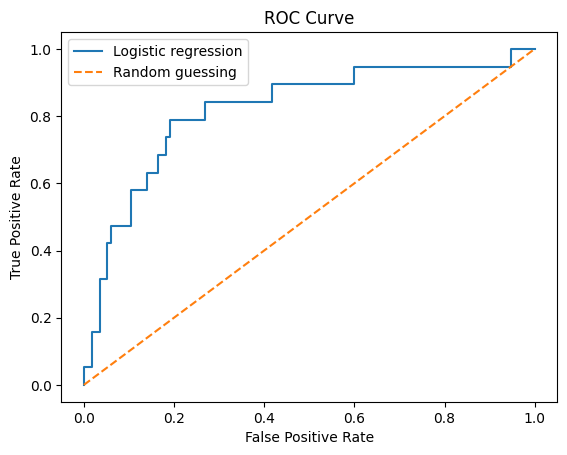

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob= model.predict_proba(X_test_scaled)[:, 1]
fpr,tpr,thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr,tpr, label="Logistic regression")
plt.plot([0, 1],[0, 1], linestyle="--", label= "Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

The ROC curve shows how well the model separates customers who leave from customers who stay, across every possible cutoff. The side axis (True Positive Rate) is the share of leaving customers the model caught, and the bottom axis (False Positive Rate) is the share of loyal customers it wrongly flagged. The dashed diagonal line is random guessing. My curve sits above that line, so the model is better than guessing.

In [23]:
roc_auc_score(y_test, y_prob)

np.float64(0.8196796338672768)

The AUC is 0.82. This means that if I pick one customer who left and one who stayed, the model gives the one who left a higher chance of leaving about 82 times out of 100. Guessing would give 0.5, so 0.82 is good. This shows the model ranks customers well, even though the default 0.5 cutoff caught only 3 of 19 leaving customers. A lower cutoff would catch more of them, but it would also give more false alarms.